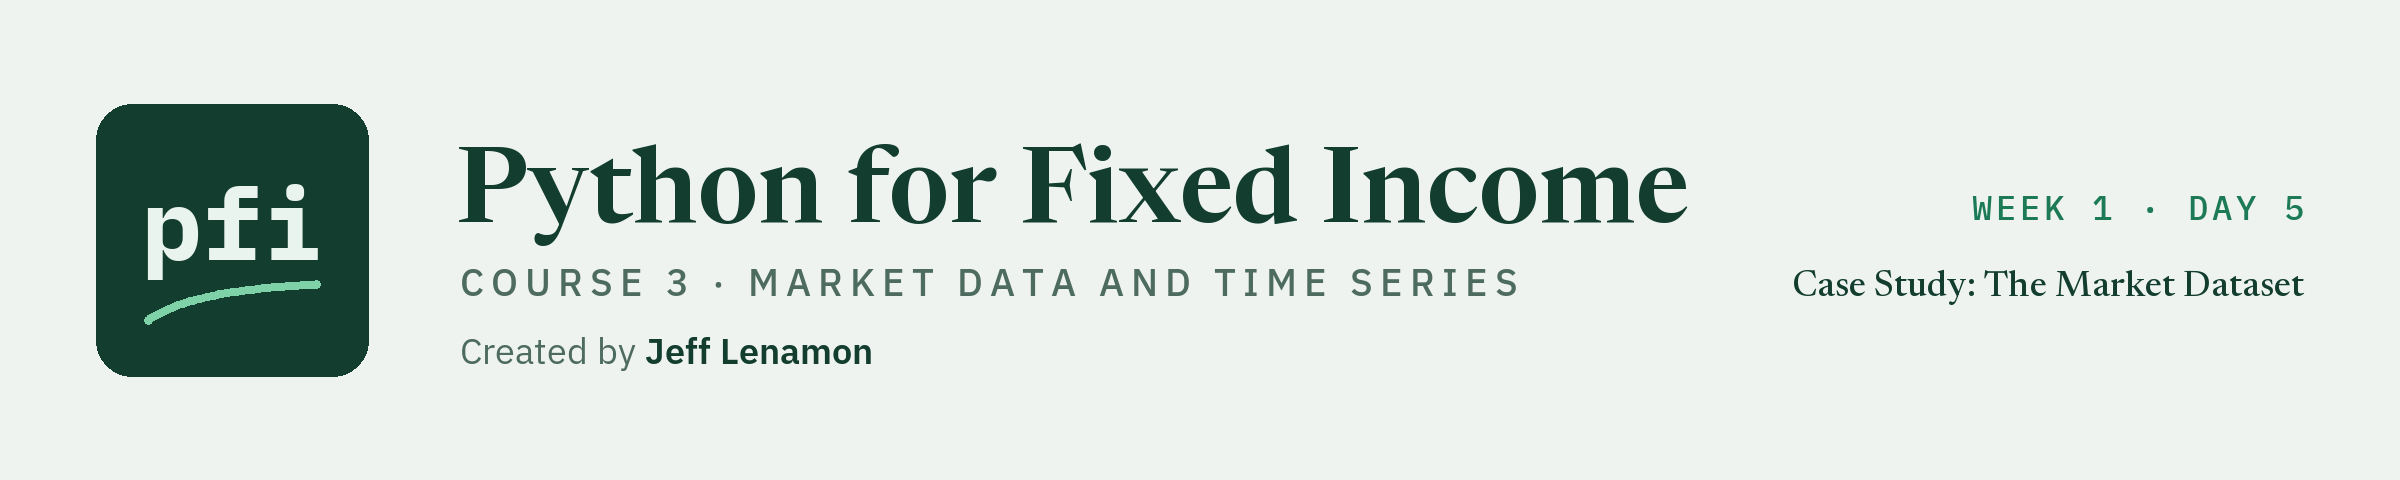

# Case Study: The Market Dataset

Week 1, Day 5. A cache that gives back every digit and refuses licensed data, then the daily dataset weeks 2 and 3 start from, checked clean.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day5/05_case_study_the_market_dataset.ipynb)

## Problem Definition

### Context

The desk lead's fifth note:

> Week 1 ends today, and weeks 2 and 3 start from one dataset. First the pulls: a morning of reruns must not send FRED hundreds of requests, so keep a copy of each series for the day, and prove the copy gives back every digit. ICE and Moody's series must never be stored: make the code refuse them, not a habit. Show me the same curve comes from FRED through that copy, equal to our file, and tag the week. Then build the daily dataset, five Treasury tenors and two credit spreads, one row per market day, and prove it clean with every check of the week. Describe the data: no view on any rate or spread.

### Objective

You are the desk's analyst: answer the five asks with your own `marketdata.py`, and make every check an `assert`.

### The Data

<table align="left">
<tr><th align="left">File</th><th align="left">What it holds</th><th align="left">Units</th><th align="left">Licence</th></tr>
<tr><td align="left"><code>treasury_par_yields.csv</code></td><td align="left">Treasury par yields, 14 tenors, 2,940 market days</td><td align="left">percent</td><td align="left">Public domain</td></tr>
<tr><td align="left"><code>course3_synthetic_spreads.csv</code></td><td align="left"><code>ig_spread_bp</code> and <code>hy_spread_bp</code> on the same dates</td><td align="left">bp</td><td align="left"><b>Synthetic</b>: invented for this course, not ICE, Moody's, or any index</td></tr>
</table>
<br clear="left">

### How We Will Work

![Nine steps in two rows. The module: 5.1 eleven requests a run, 5.2 write_cache and read_cache, 5.3 cached_fred_series, 5.4 tag the week. The dataset: 5.5 the curve from FRED, 5.6 ICE and Moody's as metadata, 5.7 the curve checked, 5.8 the spreads joined, 5.9 the dataset](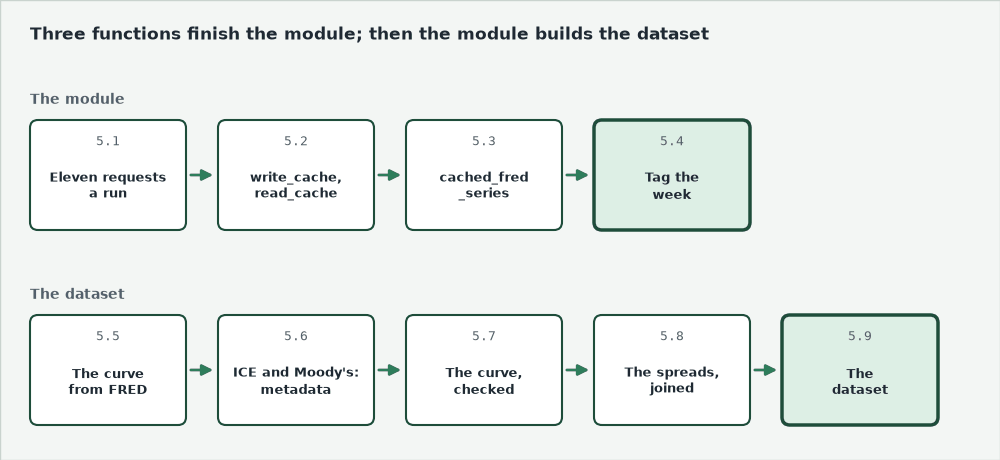)

**Three functions finish week 1's module; then the module builds the dataset.**

## 5.1 Eleven Requests a Run

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 04 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(5)

Work folder pfi_course3_05_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 04 left it, 4 commits


### The Module as Notebook 04 Left It

Q. How many tests pass this morning?

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................                                                        [100%]
17 passed in 0.50s



### Imports

Q. Load the libraries and your module.

In [3]:
import importlib

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import marketdata as md

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### Two Constants

Q. Which FRED series hold the Treasury curve, and which series may never be stored?

In [4]:
%%writefile -a marketdata.py


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")

Appending to marketdata.py


### What a Morning Costs

Q. One run of the whole curve sends one request per series. What do twelve quick reruns send?

In [5]:
# the file changed, so read it again
importlib.reload(md)
requests_per_run = len(md.FRED_TREASURY)
# without a cache every run asks FRED again; with one, only the first run of the day does
print(f'Twelve runs: {12 * requests_per_run} requests without a cache, '
      f'{requests_per_run} with one')

Twelve runs: 132 requests without a cache, 11 with one


Notebook 02's requests chart showed where quick uncached runs lead: the eleventh passes FRED's 120 requests a minute.
A copy on disk is also faster, and still there when FRED is down.

**Without a cache every rerun costs 11 more requests; with one, the whole day costs 11.**

## 5.2 A Copy That Gives Back Every Digit: `write_cache` and `read_cache`

![A dated series goes into write_cache, which writes cache/treasury_10yr.csv: the header date,treasury_10yr then 2015-01-02,2.12 and 2015-01-05,2.04. read_cache reads it back into the same series, every digit. No float_format on the way out, float_precision round_trip on the way in](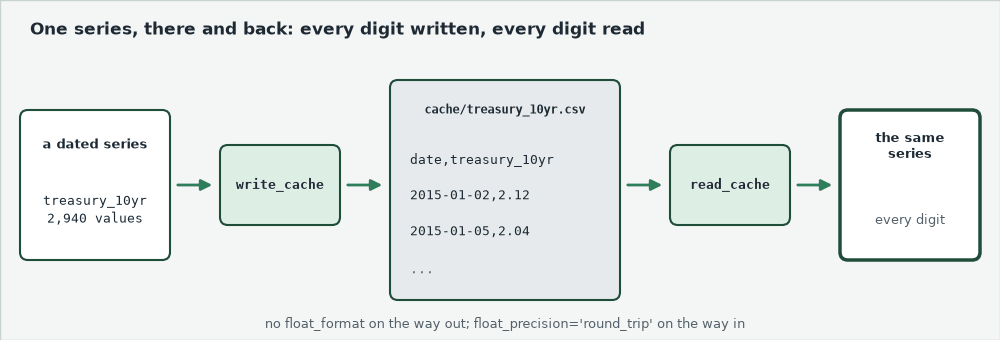)

The cache is a folder, `cache/`, one CSV per series.
Notebook 01's `.gitignore` already keeps `cache/` out of Git.

### Append Them, Docstring First

Q. Read both docstrings, then append the two functions.

In [6]:
%%writefile -a marketdata.py


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")

Appending to marketdata.py


`mkdir(parents=True, exist_ok=True)` makes the folder and any folder above it, and is quiet if it exists.
`index_label=` names the date column, and `lineterminator=` sets the line ending.

### Cache the 10 Yr

Q. Write the Treasury file's 10 Yr to the cache. What is in the file?

In [7]:
# the module changed, so read it again; then the Treasury file, read as in every notebook
importlib.reload(md)
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
# the name becomes the file name; DGS10 is kept for the live pull in 5.5
ten_year = treasury['10 Yr'].rename('treasury_10yr')
cache_dir = work / 'cache'
cached_path = md.write_cache(ten_year, cache_dir)
print(cached_path.read_text(encoding='utf-8')[:50])

date,treasury_10yr
2015-01-02,2.12
2015-01-05,2.04


### Read It Back

Q. Is the series that comes back exactly the one that went in?

In [8]:
# the file read back by name
back = md.read_cache('treasury_10yr', cache_dir)
# check_exact=True: every value equal to the last bit, with the same dates, name and type
pd.testing.assert_series_equal(back, ten_year, check_exact=True)
print(f'{len(back):,} of {len(ten_year):,} values back, every one exact')

2,940 of 2,940 values back, every one exact


### Predict 1: The Same File, Pandas' Default Reader

**Predict 1**

The 10 Yr has two decimals.
Cache it divided by 3 instead, with every digit a float holds, and read it back with plain `pd.read_csv`, no `float_precision`.

Q. How many of the 2,940 values come back different? Write down a number.

In [9]:
# a third of each yield, cached, then read back by both readers
thirds = (treasury['10 Yr'] / 3).rename('treasury_10yr_thirds')
md.write_cache(thirds, cache_dir)
plain = pd.read_csv(cache_dir / 'treasury_10yr_thirds.csv', parse_dates=['date'], index_col='date')
default_wrong = (plain['treasury_10yr_thirds'] != thirds).sum()
exact_wrong = (md.read_cache('treasury_10yr_thirds', cache_dir) != thirds).sum()
print(f'pandas default: {default_wrong} differ; read_cache: {exact_wrong} differ')

pandas default: 599 differ; read_cache: 0 differ


Each slip is in the last digit.
The file was right both times: only the reader changed.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Open a CSV of the 2,940 thirds</td><td align="left"><code>md.read_cache(...)</code></td><td align="left">File, Open</td><td align="left">Python 0 changed; Excel 2,226, the largest by 9.8e-15</td></tr>
</table>
<br clear="left">

### Predict 2: Two Decimals

**Predict 2**

Q. The 10 Yr as first cached, two decimals, through the same default reader. How many differ?

A) None
B) About the same share as the thirds
C) A few dozen

In [10]:
# the two-decimal file from above, through pandas' default reader
plain_two = pd.read_csv(cache_dir / 'treasury_10yr.csv', parse_dates=['date'], index_col='date')
print(f"two decimals: {(plain_two['treasury_10yr'] != ten_year).sum()} of 2,940 differ")

two decimals: 0 of 2,940 differ


A: the reader slips only on long numbers, so the round-trip test below also caches thirds.

### Ask for a File That Is Not There

Q. What happens when the cache has no file for a series?

In [11]:
# no DGS2.csv in the cache
md.read_cache('DGS2', cache_dir)

FileNotFoundError: no cache file DGS2.csv in the folder cache

An error, never an empty series: an empty series would look like a series with no data.

### Two Tests

Q. Add the two tests.

In [12]:
%%writefile -a test_marketdata.py


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)

Appending to test_marketdata.py


### Run pytest

Q. Do they pass?

In [13]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................                                                      [100%]
19 passed in 0.50s



**Every digit comes back because `read_cache` asks for every digit. Next, the function that decides whether to ask FRED at all.**

## 5.3 `cached_fred_series`, and Why It Refuses Licensed Series

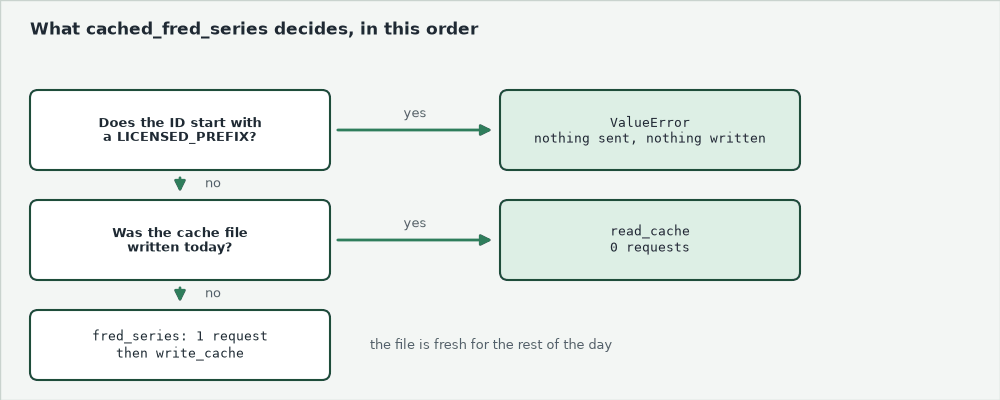

The refusal comes first, before a request or a file.

### Append It, Docstring First

Q. Read the docstring, then append the function.

In [14]:
%%writefile -a marketdata.py


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series

Appending to marketdata.py


It may send a request, so it runs only in 5.5's live cells; its two rules show without the network.

### Fresh Means Written Today

Q. Is the cached 10 Yr fresh? Move its time back a day and ask again.

In [15]:
# the date and datetime types, as the module imports them
from datetime import date, datetime
# stat() reads a file's details: st_mtime is when it was last written, in seconds
written = datetime.fromtimestamp(cached_path.stat().st_mtime).date()
print(f'Written today: {written == date.today()}')
# os.utime sets a file's times: both moved back 24 hours, as if written yesterday
yesterday = cached_path.stat().st_mtime - 24 * 60 * 60
os.utime(cached_path, (yesterday, yesterday))
written = datetime.fromtimestamp(cached_path.stat().st_mtime).date()
print(f'After moving it back a day: {written == date.today()}')

Written today: True
After moving it back a day: False


`datetime.fromtimestamp` turns seconds into a date and time, and `date.today()` is the computer's date.
Tomorrow the whole cache is old, and each series is pulled once.

### The Refused IDs

Q. Which of these IDs may be cached?

In [16]:
# the module changed, so read it again
importlib.reload(md)
# startswith takes a tuple: True if the ID starts with any of them
for series_id in ['DGS10', 'DGS2', 'BAMLC0A0CM', 'BAMLH0A0HYM2', 'BAA10Y', 'DBAA']:
    refused = series_id.startswith(md.LICENSED_PREFIXES)
    print(f"{series_id:13} {'refused: licensed' if refused else 'may be cached'}")

DGS10         may be cached
DGS2          may be cached
BAMLC0A0CM    refused: licensed
BAMLH0A0HYM2  refused: licensed
BAA10Y        refused: licensed
DBAA          refused: licensed


### The Test That Proves No Request Was Sent

Q. Add the third test.

In [17]:
%%writefile -a test_marketdata.py


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()

Appending to test_marketdata.py


`monkeypatch.setattr` swaps in the stand-in, as in notebook 02.
`match=` also checks the error's message holds the word.

### Run pytest

Q. Does week 1's module pass?

In [18]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................                                                     [100%]
20 passed in 0.50s



**No request, no file: a check that stops beats a habit. Week 1's module is complete.**

## 5.4 Tag the Week

### What Git Sees

Q. What changed, and is the cache kept out?

In [19]:
# !! marks an ignored file, as in notebook 01
!git -C "{work}" status --short --ignored
!git -C "{work}" check-ignore -v cache/treasury_10yr.csv

 M marketdata.py
 M test_marketdata.py
!! __pycache__/
!! bondmath.py
!! cache/
!! course3_excel_reference.csv
!! course3_fred_format_dgs10.json
!! course3_synthetic_spreads.csv
!! treasury_par_yields.csv
.gitignore:4:cache/	cache/treasury_10yr.csv


`cache/` is ignored by line 4 of notebook 01's `.gitignore`.
The data files and `bondmath.py` are copies the setup put on Git's local ignore list, so they show `!!` too.

### Read the Diff, Commit

Q. How big is today's change? Commit it.

In [20]:
# the size of the change, then the commit, as in Course 2
!git -C "{work}" diff --stat
subject = 'Notebook 05: write_cache, read_cache, and cached_fred_series'
body = 'Week 1 ends: one request per series per day, and licensed data stays in memory.'
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "{subject}" -m "{body}"

 marketdata.py      | 70 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 31 ++++++++++++++++++++++++
 2 files changed, 101 insertions(+)


### Name the Week

Q. Tag the commit that ends week 1.

In [21]:
# a tag is a name fixed to one commit, as in Course 2's New Issue Calendar
!git -C "{work}" tag week1
!git -C "{work}" log --oneline --decorate

ba73980 (HEAD -> main, tag: week1) Notebook 05: write_cache, read_cache, and cached_fred_series
9f01b1c Notebook 04: last_per_period and value_as_of
a439502 Notebook 03: missing_weekdays, align, and stale_runs
ceea769 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


`main` moves on with tomorrow's commit; `week1` stays here, as Course 2's picture of a tag showed.

**`week1` names the module as the week ends: three functions, three tests, and a cache Git never sees. Now the copy on real data.**

## 5.5 Live: The Curve From FRED, Through the Cache

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

### The Key Cell

Q. Is there a key on this machine?

In [22]:
from pathlib import Path

# your .env file: in my_bondmath, outside every repository. The key cell looks here last.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# what every live cell prints when no key was found
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen; set True only on your own machine
SHOW_LICENSED_VALUES = False

In [23]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


### Eleven Series, Checked Against the File

Q. Pull every Treasury series through the cache, check each against the file, then pull them all again.

In [24]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    live_cache = work / 'cache'
    live_start = '2015-01-01'
    for live_id, live_tenor in md.FRED_TREASURY.items():
        # today's file if there is one, otherwise one request, then cached
        live_series = md.cached_fred_series(live_id, fred_key, live_cache, start=live_start)
        live_series = live_series.dropna()
        # the check: on every date both have, FRED's value equals the file's, in percent
        live_common = live_series.index.intersection(treasury.index)
        live_gap = (live_series[live_common] - treasury.loc[live_common, live_tenor]).abs().max()
        assert len(live_common) > 0 and live_gap <= 1e-9, f'{live_id} differs from the file'
        print(f'{live_id:7} {live_tenor:6} {len(live_common):,} dates in both, '
              f'largest gap {live_gap:.1e}')
    # the second pass: every file was written today, so no request is sent
    for live_id in md.FRED_TREASURY:
        live_again = md.cached_fred_series(live_id, fred_key, live_cache, start=live_start)
        assert live_again.equals(md.read_cache(live_id, live_cache))
    print(f'Second pass: {len(md.FRED_TREASURY)} series from {live_cache.name}/, no request sent')

Live cell skipped: no FRED key was found. Every other cell runs without one.


### With Your Key

Eleven lines, each with a largest gap of `0.0e+00` percent: FRED's `DGS` series hold the Treasury file's published values.
The second pass reads eleven files and sends nothing.

**The cache works on the real thing. FRED carries credit series too.**

## 5.6 ICE and Moody's on FRED: Metadata Only

Three series a credit desk knows are on FRED: ICE BofA's investment grade and high yield option-adjusted spreads, `BAMLC0A0CM` and `BAMLH0A0HYM2`, and Moody's Baa yield less the 10-year Treasury, `BAA10Y`.
A free key downloads them; the providers own them.

### What the Notes Say

<table align="left">
<tr><th align="left">Series</th><th align="left">What the notes say (read 2026-10-04)</th></tr>
<tr><td align="left">ICE BofA</td><td align="left">"Starting in April 2026, this series will only include 3 years of observations."</td></tr>
<tr><td align="left">ICE BofA</td><td align="left">"... being provided for your internal use only and you are not authorized or permitted to publish, distribute or otherwise furnish Top Level Data to any third-party ..."</td></tr>
<tr><td align="left">ICE BofA</td><td align="left">"When the last calendar day of the month takes place on the weekend, weekend observations will occur as a result of month ending accrued interest adjustments."</td></tr>
<tr><td align="left">Moody's</td><td align="left">"MOODY'S INFORMATION MAY NOT BE COPIED OR OTHERWISE REPRODUCED ... OR STORED FOR SUBSEQUENT USE ... WITHOUT MOODY'S PRIOR WRITTEN CONSENT."</td></tr>
</table>
<br clear="left">

Sources: https://fred.stlouisfed.org/series/BAMLC0A0CM and https://fred.stlouisfed.org/series/BAA10Y.
FRED's terms add that a series whose notes say "Copyright" is owned by a third party (https://fred.stlouisfed.org/docs/api/terms_of_use.html).

![Two lanes from FRED. Treasury DGS series: FRED, then the cache, then a file and the screen; Git ignores the cache. ICE BofA and Moody's: FRED, then memory only, then metadata on screen; values only on your own screen with SHOW_LICENSED_VALUES = True; never a cache, a file, a slide, or a video](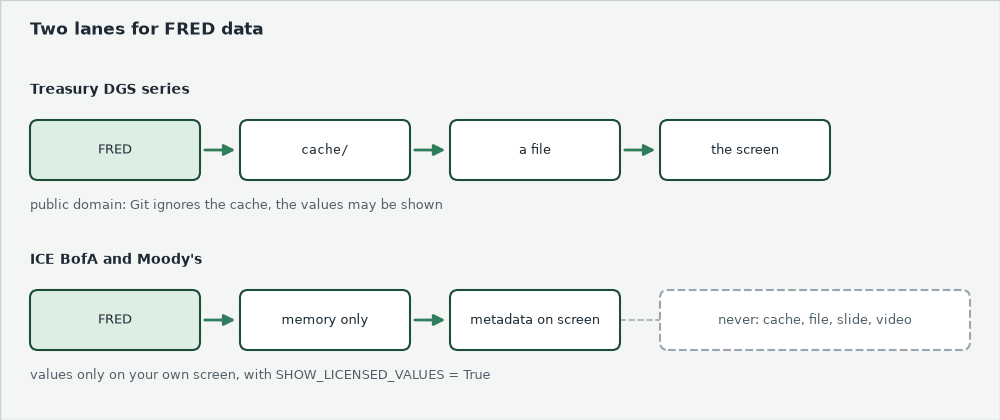)

A saved notebook, a slide and a video all publish, so the live cell prints metadata only: rows, first and last date, `.` rows, weekend rows.

### Pulled Into Memory, Described

Q. Pull the three series with `fred_series` and describe each pull.

In [25]:
# a live cell: licensed series, metadata only
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    for live_id in ['BAMLC0A0CM', 'BAMLH0A0HYM2', 'BAA10Y']:
        # into memory only: fred_series, never cached_fred_series, and nothing is written
        live_series = md.fred_series(live_id, fred_key)
        live_weekend = (live_series.index.dayofweek >= 5).sum()
        print(f'{live_id}: percent, {len(live_series):,} rows, {live_series.index[0].date()} to '
              f'{live_series.index[-1].date()}, {live_series.isna().sum()} . rows, '
              f'{live_weekend} weekend rows')
        # in percent, so every value is between 0 and 30, never in bp
        assert live_series.dropna().between(0, 30).all(), f'{live_id}: a value outside 0 to 30'
        if live_id.startswith('BAML'):
            # Timestamp.today() is now; DateOffset steps back whole years and months
            live_floor = pd.Timestamp.today() - pd.DateOffset(years=3, months=1)
            assert live_series.index[0] >= live_floor, f'{live_id}: more than three years'
        if SHOW_LICENSED_VALUES:
            # your screen only, in bp: never saved, shared, or recorded
            print((live_series.dropna() * 100).tail(5).round(1))
            (live_series * 100).plot(title=f'{live_id} in bp (licensed: your screen only)')
            plt.show()
    # nothing licensed reached the cache
    for live_path in (work / 'cache').glob('*.csv'):
        assert not live_path.name.startswith(md.LICENSED_PREFIXES), f'{live_path.name} is licensed'
    print('Cache: no licensed series written')

Live cell skipped: no FRED key was found. Every other cell runs without one.


### With Your Key

One line per series: about three years of daily ICE rows, with weekend rows at month ends, and a longer `BAA10Y`; then the cache line.
Values appear only with `SHOW_LICENSED_VALUES = True` on your own machine: keep them to yourself.

**Licensed values never reach a cache, a file, a slide, or a video, so the dataset's credit columns are synthetic, and labelled so. Now the case study.**

> STORY: Three years, and no more. In April 2026 ICE BofA's series on FRED were cut to three years of history. When this course was written, a request to one of them for 2010 came back with HTTP status 200 and zero observations: an empty answer, not an error. `fred_series` raises on exactly that, as notebook 02 tested. Source: FRED series notes, https://fred.stlouisfed.org/series/BAMLC0A0CM (read 2026-10-04).

## 5.7 The Curve, Checked

### Dates: Unique, Ascending, Weekdays

Q. Are the file's dates unique, in order, and all Monday to Friday?

In [26]:
# is_unique and is_monotonic_increasing, from Course 1's First Look and Treasury Yields
assert treasury.index.is_unique and treasury.index.is_monotonic_increasing, 'dates out of order'
# dayofweek counts Monday as 0, so 5 and 6 are Saturday and Sunday
weekend_rows = (treasury.index.dayofweek >= 5).sum()
assert weekend_rows == 0, 'a weekend date'
print(f'{len(treasury):,} dates, unique and ascending, {weekend_rows} on a weekend')

2,940 dates, unique and ascending, 0 on a weekend


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Weekend dates</td><td align="left"><code>(treasury.index.dayofweek &gt;= 5).sum()</code></td><td align="left"><code>=SUMPRODUCT(--(WEEKDAY(A2:A2941,2)&gt;5))</code></td><td align="left">0</td></tr>
<tr><td align="left">Repeated dates</td><td align="left"><code>treasury.index.is_unique</code></td><td align="left"><code>=ROWS(A2:A2941)-ROWS(UNIQUE(A2:A2941))</code></td><td align="left">0</td></tr>
<tr><td align="left">Dates out of order</td><td align="left"><code>treasury.index.is_monotonic_increasing</code></td><td align="left"><code>=SUMPRODUCT(--(A3:A2941&lt;=A2:A2940))</code></td><td align="left">0</td></tr>
</table>
<br clear="left">

### The Market's Own Calendar

Q. How many weekdays have no row?

In [27]:
# notebook 03's missing_weekdays: every weekday with no row
missing = md.missing_weekdays(treasury.index)
assert len(missing) == 126, 'the missing weekdays changed since notebook 03'
print(f'{len(missing)} weekdays with no row, the last {missing[-1].date()}')

126 weekdays with no row, the last 2026-09-07


### Predict 3: Every Tenor on Every Row?

**Predict 3**

Q. The file has 14 tenors and 2,940 rows. On how many rows does every tenor have a value? Write down a number.

In [28]:
# dropna keeps only the rows with no blank cell
print(f'{len(treasury.dropna()):,} rows have all 14 tenors')

408 rows have all 14 tenors


### Three Tenors Start Late

Q. Which tenors start after the file's first date, and do they have gaps once they start?

In [29]:
# a dict comprehension, {key: value for ...}, makes one pair per tenor, as a list one makes items
first_dates = pd.Series({tenor: treasury[tenor].first_valid_index() for tenor in treasury.columns})
# each late tenor: blank rows before its first date, then gaps after it
for tenor, start in first_dates[first_dates > treasury.index[0]].items():
    blanks = treasury.loc[:start, tenor].isna().sum()
    gaps = treasury.loc[start:, tenor].isna().sum()
    print(f'{tenor:9} from {start.date()}: {blanks:,} blank rows before, {gaps} after')

1.5 Month from 2025-02-18: 2,532 blank rows before, 0 after
2 Mo      from 2018-10-16: 949 blank rows before, 0 after
4 Mo      from 2022-10-19: 1,951 blank rows before, 0 after


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Blank cells of the 4 Mo, column F</td><td align="left"><code>treasury['4 Mo'].isna().sum()</code></td><td align="left"><code>=COUNTBLANK(F2:F2941)</code></td><td align="left">1,951</td></tr>
<tr><td align="left">The 4 Mo's first date</td><td align="left"><code>treasury['4 Mo'].first_valid_index()</code></td><td align="left"><code>=XLOOKUP(TRUE,F2:F2941&lt;&gt;"",A2:A2941)</code></td><td align="left">2022-10-19</td></tr>
</table>
<br clear="left">

### When Each Tenor Has Values

Q. Draw each tenor's span.

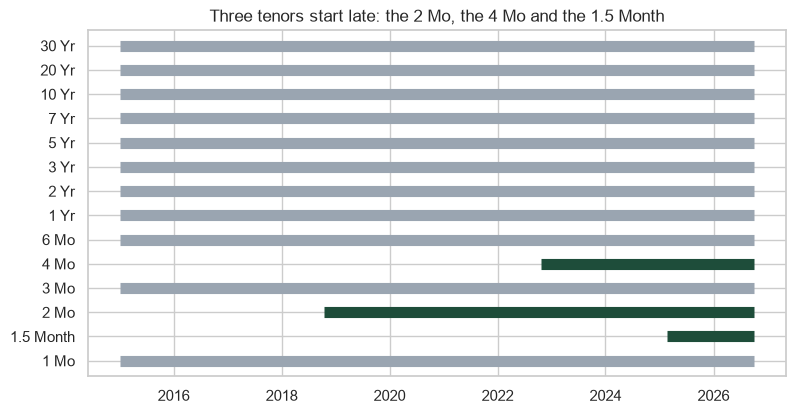

In [30]:
# the late starters in dark green, the rest in grey
late = first_dates > treasury.index[0]
fig, ax = plt.subplots(figsize=(9, 4.5))
# hlines draws flat lines: one per height, from each tenor's first date to the last
ax.hlines(range(14), first_dates, treasury.index[-1], linewidth=8,
          colors=['#1E4D3A' if is_late else '#9AA5B1' for is_late in late])
ax.set_yticks(range(14), first_dates.index)
ax.set_title('Three tenors start late: the 2 Mo, the 4 Mo and the 1.5 Month')
plt.show()

**A blank before a tenor starts is not a missing value: nothing was published. The dataset takes five tenors that run the whole file.**

## 5.8 The Spreads, Joined

### The Second File

Q. Load the synthetic spreads. Do they hold the curve's dates?

In [31]:
# the synthetic spreads, in bp, read as the Treasury file is
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
# notebook 03's align, both ways
pair = {'10 Yr': treasury['10 Yr'], 'ig_spread_bp': spreads['ig_spread_bp']}
inner, outer = md.align(pair, how='inner'), md.align(pair, how='outer')
print(f'inner {len(inner):,} rows, outer {len(outer):,} rows, {outer.isna().sum().sum()} blank')

inner 2,940 rows, outer 2,940 rows, 0 blank


![The week of Labor Day 2026, Friday 4 to Friday 11 September, for the curve's 10 Yr and the synthetic IG spread side by side. Both have rows on the two Fridays and on Tuesday to Thursday, and neither has the weekend or Monday 7, the holiday. An inner join and an outer join keep the same rows](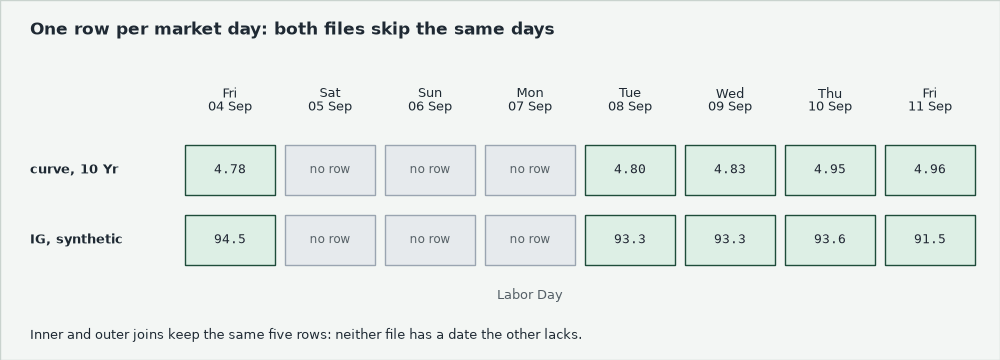)

### Two Files, Stacked and Joined

Q. Stack two halves of the curve file, and join the spreads beside the curve.

In [32]:
# the file split at 2026 and stacked again with Course 1's concat
stacked = pd.concat([treasury.loc[:'2025'], treasury.loc['2026':]])
# the spreads beside every curve row, matched on the date, with Course 1's join
merged = treasury.join(spreads)
print(f'stacked {len(stacked):,} rows, equal to the file: {stacked.equals(treasury)}')
print(f'merged {len(merged):,} rows, {merged.shape[1] + 1} columns with the date')

stacked 2,940 rows, equal to the file: True
merged 2,940 rows, 17 columns with the date


**Excel side by side.** Power Query, Data, Get Data, Combine Queries:

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Stack 2,750 and 190 rows</td><td align="left"><code>pd.concat</code></td><td align="left">Append: <code>Table.Combine({First, Second})</code></td><td align="left">2,940 rows, 15 columns</td></tr>
<tr><td align="left">Join on the date</td><td align="left"><code>treasury.join(spreads)</code></td><td align="left">Merge: <code>Table.NestedJoin(... JoinKind.LeftOuter)</code>, then <code>Table.ExpandTableColumn</code></td><td align="left">2,940 rows, 17 columns, spreads as text (<code>98.8</code>, <code>334.7</code>) until <code>Table.TransformColumnTypes(..., "en-US")</code></td></tr>
<tr><td align="left">A spread beside each date</td><td align="left"><code>md.align</code></td><td align="left"><code>=XLOOKUP($A2,Spreads!$A$2:$A$2941,Spreads!$B$2:$B$2941)</code>, filled down</td><td align="left">0 <code>#N/A</code></td></tr>
</table>
<br clear="left">

### Predict 4: Which Column Sits Still?

**Predict 4**

Yields are published to 0.01 percent, the synthetic spreads to 0.1 bp.

Q. Which of the dataset's seven columns has the most runs of 5 or more equal values?

A) A synthetic spread
B) The 3 Mo
C) The 30 Yr

In [33]:
# the dataset's five tenors, which run the whole file, and its two spreads
TENORS = ['3 Mo', '2 Yr', '5 Yr', '10 Yr', '30 Yr']
SPREADS = ['ig_spread_bp', 'hy_spread_bp']
# notebook 03's stale_runs: one row per run of 5 or more equal values
runs_of_five = pd.Series({column: len(md.stale_runs(merged[column], min_length=5))
                          for column in TENORS + SPREADS})
assert runs_of_five[SPREADS].sum() == 0, 'a synthetic spread went stale'
print(f'The {runs_of_five.idxmax()} has the most: {runs_of_five.max()}')

The 3 Mo has the most: 34


### Runs of 5 or More, by Column

Q. Draw the seven counts.

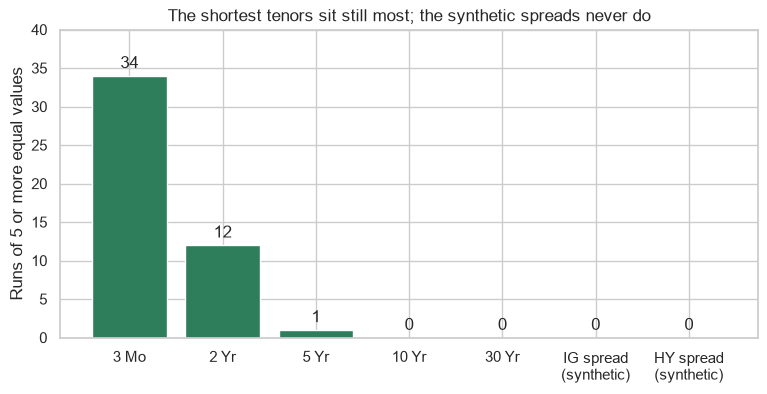

In [34]:
# one bar per column, the spreads labelled synthetic
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(['3 Mo', '2 Yr', '5 Yr', '10 Yr', '30 Yr', 'IG spread\n(synthetic)',
               'HY spread\n(synthetic)'], runs_of_five.values, color='#2E7D5B')
ax.bar_label(bars, padding=3)
ax.set_ylim(0, 40)
ax.set_title('The shortest tenors sit still most; the synthetic spreads never do')
ax.set_ylabel('Runs of 5 or more equal values')
plt.show()

B: the shortest tenors sit still most.
A repeated yield is what Treasury published, so it is kept; the stop is on the spreads.

**A spread on every market date and none on any other, and neither spread ever sits still for five days. Now the dataset.**

## 5.9 The Dataset

### Seven Columns, One Row per Market Day

Q. Build it: five tenors and two spreads, joined on the date.

In [35]:
# one column per series, yields in percent and spreads in bp
columns = {tenor: treasury[tenor] for tenor in TENORS}
columns['ig_spread_bp'] = spreads['ig_spread_bp']
columns['hy_spread_bp'] = spreads['hy_spread_bp']
dataset = md.align(columns, how='inner')
print(f'{len(dataset):,} rows, {dataset.shape[1]} columns')

2,940 rows, 7 columns


### Every Check of Week 1

Q. Is it clean?

In [36]:
# silent when every check passes
assert dataset.index.is_unique and dataset.index.is_monotonic_increasing, 'dates out of order'
assert (dataset.index.dayofweek >= 5).sum() == 0, 'a weekend date'
assert md.missing_weekdays(dataset.index).equals(missing), 'the market calendar changed'
assert dataset.notna().all().all(), 'a blank cell'
print('Unique ascending dates, no weekend, the same 126 missing weekdays, no blank')

Unique ascending dates, no weekend, the same 126 missing weekdays, no blank


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Blank looked-up spreads, column P</td><td align="left"><code>dataset.notna().all()</code></td><td align="left"><code>=COUNTBLANK(P2:P2941)</code></td><td align="left">0</td></tr>
</table>
<br clear="left">

### Month Ends of 2026

Q. Show the last market day of each month of 2026, with notebook 04's `last_per_period`.

In [37]:
# the last row of each month of 2026, each labelled with its own date
month_ends = md.last_per_period(dataset.loc['2026'], 'ME')
# format_index writes each date with Course 1's to_datetime codes, %Y-%m-%d: no time
(month_ends.style.format('{:.2f}', subset=TENORS).format('{:.1f}', subset=SPREADS)
    .format_index('{:%Y-%m-%d}')
    .background_gradient(cmap='Greens', subset=['10 Yr', 'ig_spread_bp', 'hy_spread_bp']))

,3 Mo,2 Yr,5 Yr,10 Yr,30 Yr,ig_spread_bp,hy_spread_bp
date,,,,,,,
2026-01-30,3.67,3.52,3.79,4.26,4.87,91.3,267.2
2026-02-27,3.67,3.38,3.51,3.97,4.64,95.6,287.5
2026-03-31,3.70,3.79,3.92,4.30,4.88,96.5,288.1
2026-04-30,3.68,3.88,4.02,4.40,4.98,106.8,338.1
2026-05-29,3.69,3.98,4.13,4.45,4.99,102.2,334.9
2026-06-30,3.87,4.14,4.19,4.44,4.91,100.1,345.4
2026-07-31,3.83,4.28,4.45,4.75,5.27,97.2,327.1
2026-08-31,3.91,4.34,4.49,4.75,5.25,94.3,319.9
2026-09-30,4.20,4.88,5.09,5.29,5.64,98.8,334.7


On 2026-09-30 the 10 Yr is 5.29 percent, notebook 04's month-end value.
The synthetic spreads were set to end there at 98.8 and 334.7 bp, the market-value weighted OAS of the investment grade and high yield bonds in Course 2's September book.
October's row is the file's last day so far, 2026-10-02.

### The Dataset, Drawn

Q. Draw all seven columns over the whole file.

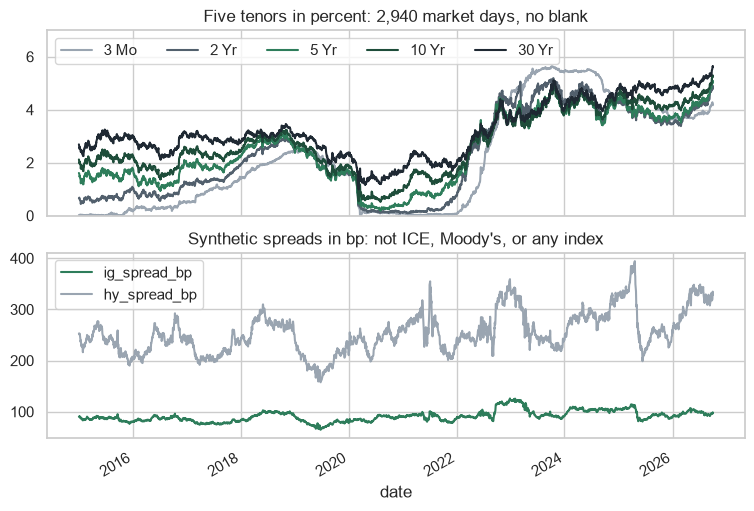

In [38]:
# two charts sharing the dates, as notebook 02's pair did; pandas' plot draws on the ax= given
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(9, 6))
dataset[TENORS].plot(ax=top, color=['#9AA5B1', '#52606D', '#2E7D5B', '#1E4D3A', '#1F2933'])
top.set_title('Five tenors in percent: 2,940 market days, no blank')
# room above the lines for the legend, in one row of five
top.set_ylim(0, 7)
top.legend(loc='upper left', ncols=5)
dataset[SPREADS].plot(ax=bottom)
bottom.set_title("Synthetic spreads in bp: not ICE, Moody's, or any index")
plt.show()

**2,940 market days, seven columns, no blank, no weekend, no repeated date, no stale spread: the dataset weeks 2 and 3 start from. The note is answered.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left">The 10 Yr through the cache</td><td align="left">2,940 of 2,940 exact</td></tr>
<tr><td align="left">Thirds: <code>read_cache</code> against the default reader</td><td align="left">0 and 599 of 2,940 differ</td></tr>
<tr><td align="left">Licensed IDs</td><td align="left">refused, no request, no folder</td></tr>
<tr><td align="left">pytest</td><td align="left">20 passed</td></tr>
<tr><td align="left">Dates</td><td align="left">2,940 unique, ascending, 0 on a weekend</td></tr>
<tr><td align="left">Missing weekdays</td><td align="left">126, as notebook 03</td></tr>
<tr><td align="left">Late tenors</td><td align="left">3, none in the dataset</td></tr>
<tr><td align="left">Spreads joined</td><td align="left">inner 2,940, outer 2,940</td></tr>
<tr><td align="left">Stale runs of 5 in the spreads</td><td align="left">0</td></tr>
<tr><td align="left">Dataset</td><td align="left">2,940 rows, 7 columns, 0 blank</td></tr>
</table>
<br clear="left">

## Bring It Home

Copy the two files into your own folder, test, commit, and tag the week there.
In a PowerShell terminal in VS Code with the course's `.venv` active, use the work folder name your setup cell printed:

```powershell
$work = "$env:TEMP\pfi_course3_05_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
python -m pytest -q test_marketdata.py
git check-ignore -v cache/DGS10.csv
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Notebook 05: write_cache, read_cache, and cached_fred_series"
git tag week1
git log --oneline --decorate -3
```

The copy replaces your two files, so anything of your own goes into the work folder first.
The data files the tests read are already there.
`check-ignore` must name notebook 01's `cache/` line; if it prints nothing, add the line before you commit.
With your key, 5.5's loop with `live_cache` set to the `cache` folder in `my_bondmath` pulls each series once a day.
In Colab, download the two files from the work folder under `/tmp`.
The work folder stays in your temp folder until you delete it.

## You Can Now

By the end of this notebook, you can:

* Say what a cache saves: FRED's limit, time, and a pull when FRED is down.
* Cache a series and read it back exactly, with `float_precision="round_trip"`.
* Use `cached_fred_series`, which pulls at most once a day and refuses a licensed series before sending anything.
* Keep ICE's and Moody's values off every saved or shared screen.
* Build a daily market dataset and prove it clean with every check of week 1.
* Tag the end of a week in Git and find the tag with `git log --decorate`.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Every exercise uses `treasury`, `spreads`, `TENORS`, `SPREADS` and `dataset` from above, and needs no key.
Replace each `...` with your code, then run the cell.
Run the next cell first.

In [39]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. Add the 7 Yr and 20 Yr to the five tenors and the two spreads, joined as in 5.9. Store the new table's shape in **ex1_shape** and its 7 Yr on 2026-09-30, in percent, in **ex1_seven**.

In [40]:
ex1_shape = ...
ex1_seven = ...
check('Exercise 1 shape', ex1_shape, (2940, 9))
check('Exercise 1 the 7 Yr on 2026-09-30', ex1_seven, 5.19)

Exercise 1 shape: not attempted yet
Exercise 1 the 7 Yr on 2026-09-30: not attempted yet


### Exercise 2

Q. Is the synthetic high yield spread above the investment grade spread on every row? Store `True` or `False` in **ex2_all_above** and the narrowest gap, high yield less investment grade in bp, in **ex2_narrowest**, and print its date.

In [41]:
ex2_all_above = ...
ex2_narrowest = ...
check('Exercise 2 above on every row', ex2_all_above, True)
check('Exercise 2 narrowest gap', ex2_narrowest, 91.5)

Exercise 2 above on every row: not attempted yet
Exercise 2 narrowest gap: not attempted yet


### Exercise 3

Q. Add `dataset_checks(frame)` to your module, docstring first: `None` when all pass, else `ValueError` at the first failed check, in order: `_check_index`; no weekend (message: `weekend`); no blank (`missing`); no run of 5 or more in a `_bp` column (`stale`, with `stale_runs`). Add `test_dataset_checks_stop_on_first_failure`: one three-row frame that passes, three that raise. Run pytest and reload. Store whether the dataset passes in **ex3_passes**. Move a copy back a day, `shifted.index = dataset.index - pd.Timedelta(days=1)` (an `.index =` line replaces the row labels), and store whether it raises with `weekend` in **ex3_caught**.

In [42]:
%%writefile -a marketdata.py


# Exercise 3: write dataset_checks(frame) below this line

Appending to marketdata.py


In [43]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_dataset_checks_stop_on_first_failure() below this line

Appending to test_marketdata.py


In [44]:
# run pytest, reload the module, then store the two answers
ex3_passes = ...
ex3_caught = ...
check('Exercise 3 the dataset passes', ex3_passes, True)
check('Exercise 3 the shifted dataset is caught', ex3_caught, True)

Exercise 3 the dataset passes: not attempted yet
Exercise 3 the shifted dataset is caught: not attempted yet


### Exercise 4: AI check

You gave an AI assistant the docstring below as the request: the docstring is the prompt.
This came back, written for this course in the style of an assistant's answer.
`tz_localize('UTC')` reads a date with no time zone as midnight UTC, `tz_convert` moves it to another zone's clock, and `normalize()` drops the time of day.

In [45]:
# written for this course in the style of an AI assistant's answer.
# It runs, and it contains one bug.
def build_market_dataset(curve_path, spreads_path, tenors):
    """Build the daily market dataset from the Treasury file and the synthetic spreads.

    Units: yields in percent and spreads in bp, as the files hold them.
    Convention: one row per date of the Treasury file, each the US business date the values are
    published for, with the spreads of that same date beside the curve. Dates are calendar dates
    with no time and no time zone: nothing is localized or converted.
    """
    curve = pd.read_csv(curve_path, parse_dates=['date'], index_col='date',
                        float_precision='round_trip')[tenors]
    spreads = pd.read_csv(spreads_path, parse_dates=['date'], index_col='date',
                          float_precision='round_trip')
    # put every date on New York time to be safe, then keep the calendar date
    for frame in (curve, spreads):
        frame.index = (frame.index.tz_localize('UTC').tz_convert('America/New_York')
                       .normalize().tz_localize(None))
    # the spreads beside the curve, on the dates both files have
    return curve.join(spreads, how='inner')

Q. The Treasury file starts on Friday 2015-01-02. What are the first three dates of the dataset this builds?

In [46]:
# the assistant's dataset, then its first three dates as text
dataset_ai = build_market_dataset('treasury_par_yields.csv', 'course3_synthetic_spreads.csv',
                                  TENORS)
print([str(day.date()) for day in dataset_ai.index[:3]])

['2015-01-01', '2015-01-04', '2015-01-05']


Q. Test it against its docstring before you trust it.

In [47]:
# 2026-09-30 must hold that day's values, and every date must be the file's
file_dates = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'])['date']
assert dataset_ai.loc['2026-09-30', '10 Yr'] == 5.29, "2026-09-30 does not hold that day's 10 Yr"
assert dataset_ai.loc['2026-09-30', 'ig_spread_bp'] == 98.8, "2026-09-30's spread is another day's"
assert dataset_ai.index.equals(pd.DatetimeIndex(file_dates)), "the dates are not the file's"
print("Every date is the file's, and 2026-09-30 holds 5.29 percent and 98.8 bp")

AssertionError: 2026-09-30 does not hold that day's 10 Yr

Q. Fix the function, run it and the test again, then store the fixed dataset's 10 Yr on 2026-09-30 in **ex4_ten**, its `ig_spread_bp` that day in **ex4_ig**, and whether its dates equal `treasury.index` in **ex4_same_dates**.

In [48]:
ex4_ten = ...
ex4_ig = ...
ex4_same_dates = ...
check('Exercise 4 the 10 Yr on 2026-09-30', ex4_ten, 5.29)
check('Exercise 4 the spread on 2026-09-30', ex4_ig, 98.8)
check('Exercise 4 the same dates', ex4_same_dates, True)

Exercise 4 the 10 Yr on 2026-09-30: not attempted yet
Exercise 4 the spread on 2026-09-30: not attempted yet
Exercise 4 the same dates: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">A day's copy of each series</td><td align="left"><code>cached_fred_series</code>: 11 requests a morning, every digit back</td></tr>
<tr><td align="left">Never store ICE or Moody's</td><td align="left">Refused in code before any request, and tested</td></tr>
<tr><td align="left">The curve from FRED</td><td align="left">Equal to the file on every common date, with your key</td></tr>
<tr><td align="left">The week tagged</td><td align="left"><code>week1</code></td></tr>
<tr><td align="left">The daily dataset</td><td align="left">2,940 market days, five tenors, two synthetic spreads, every check passed</td></tr>
</table>
<br clear="left">

Be proud: a desk trusts a number because someone checked what sits under it, and this week you built the checks.

Next, Changes in bp and Percent (notebook 06) measures what the data did, starting with a change in basis points.